# Compare annual-mean perturbation: 10-member ensemble mean vs. single member 2

Both pipelines' `--annual` mode perturbs the **exact same real ERA5 archive** with a
single, non-seasonal stage-03 delta (`DELTA_DIR/ann.nc`), and both were run with
`--years 1984 --annual`. The only difference is *which* future-minus-current LENS2
warming signal gets averaged into that one annual-mean delta:

- **ens10** (`/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW_ENS10`, perturbed output under
  `.../wpsv4.5_mpas_LENS2PGW_ens10mean_annualmean`): the **10-member smbb-ensemble
  mean** annual climatology delta -- each of 10 LENS2 members' own 30-year
  climatology averaged together (12 calendar months, then averaged across months)
  before differencing future minus current.
- **mem2** (`/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW`, perturbed output under
  `.../wpsv4.5_mpas_LENS2PGW_mem2_annualmean`): a **single member's own** annual
  climatology delta -- LENS2 case `1031.002` ("member 2"), no ensemble averaging.

This is the `--annual` counterpart of
`06.1_compare_ens10_vs_member2_monthlyUpdate.ipynb`: same two pipelines, same test
archive, same overall structure -- but comparing the single non-seasonal annual
delta each pipeline produces (`ann.nc`), not 12 calendar-month deltas. See
`05.2_verify_perturbation_annualMean.ipynb` (in each project) for why `--annual`
exists and how each pipeline's own annual delta was independently verified
(structural integrity, exact match against `ann.nc`, physical plausibility,
annual != any single month, cross-month consistency) before this cross-pipeline
comparison.

Two independent comparisons, covering both streams stage 04
(`04_apply_perturbation.py --annual`) produces:

- **Part A**: the main `ERA5:1984-06-*` archive -- `GHT`, `TT`, `RH` (3-D, all 37
  pressure levels) and `SKINTEMP`, `SST` (surface).
- **Part B**: the periodic `SST_UPDATE:*` stream (`ERA5_SST:*` on disk) -- a
  separate file layout/land-mask, `SST` only, with a much longer 1984 test window
  (June-December, 184 days) than the main archive's 6 June days -- and, because the
  annual delta is the same regardless of calendar month, a direct check that both
  pipelines' applied signal stays flat across all those different months.

## Setup

Both projects have a `config.py` module -- to load both without one clobbering the
other in `sys.modules`, `config.py` (a leaf module: it only imports
`pathlib`/`numpy`, never `config` or `lib` itself) is loaded twice under distinct
names via `importlib`. `04_apply_perturbation.py`'s shared constants/functions
(`SST_FLOOR_K`, `SST_FILL_THRESHOLD`, the SST-update filename regexes,
`load_ocean_mask()`, `load_annual_delta()`) only depend on `config.ERA5_IM_DIR`,
which is verified below to be identical between the two projects, so this
project's copy is reused for both rather than loading a second one.

In [1]:
import sys
sys.path.insert(0, "/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW_ENS10")  # so `import config`/`lib` below resolve

import datetime as dt
import glob
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import config as config_ens10       # this project: 10-member ensemble mean
import lib.wps_intermediate as wps  # binary WPS-intermediate-file reader (byte-identical copy in both projects)

# apply_pgw's SST_FLOOR_K / SST_FILL_THRESHOLD / SST-update filename regexes /
# load_ocean_mask() / load_annual_delta() are pipeline-agnostic logic parameterized
# only by config.ERA5_IM_DIR / config.DELTA_DIR -- verified identical between the
# two projects below, so reusing this one copy for both pipelines is correct, not
# an assumption.
_spec = importlib.util.spec_from_file_location(
    "apply_pgw", "/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW_ENS10/04_apply_perturbation.py")
apply_pgw = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(apply_pgw)

# config.py has no internal "import config"/"import lib" of its own, so loading the sibling
# single-member project's config.py under a distinct module name ("config_mem2") is safe --
# it cannot collide with config_ens10 above the way importing two same-named packages would.
_spec2 = importlib.util.spec_from_file_location(
    "config_mem2", "/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW/config.py")
config_mem2 = importlib.util.module_from_spec(_spec2)
_spec2.loader.exec_module(config_mem2)

print("ens10 (10-member ensemble mean, annual):")
print("  perturbed dir:", config_ens10.PERTURBED_IM_DIR_ANNUAL)
print("  delta dir:    ", config_ens10.DELTA_DIR / "ann.nc")
print("mem2 (single member 1031.002, \"member 2\", annual):")
print("  perturbed dir:", config_mem2.PERTURBED_IM_DIR_ANNUAL)
print("  delta dir:    ", config_mem2.DELTA_DIR / "ann.nc")

ens10 (10-member ensemble mean, annual):
  perturbed dir: /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean_annualmean
  delta dir:     /glade/derecho/scratch/mingge/MPAS_LENS2_PGW_ENS10/03_delta/ann.nc
mem2 (single member 1031.002, "member 2", annual):
  perturbed dir: /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_mem2_annualmean
  delta dir:     /glade/derecho/scratch/mingge/MPAS_LENS2_PGW/03_delta/ann.nc


## Verify the shared inputs

Confirm -- rather than assume -- that both pipelines really do perturb the same
source archive/grid and touch the same set of fields, so any difference found
below is attributable to the delta, not to different inputs or different
perturbation targets.

In [2]:
assert config_ens10.ERA5_IM_DIR == config_mem2.ERA5_IM_DIR, \
    "the two pipelines perturb different source archives -- comparison would not be apples-to-apples"
assert (config_ens10.ERA5_NX, config_ens10.ERA5_NY) == (config_mem2.ERA5_NX, config_mem2.ERA5_NY)
assert np.array_equal(config_ens10.ERA5_LAT, config_mem2.ERA5_LAT)
assert np.array_equal(config_ens10.ERA5_LON, config_mem2.ERA5_LON)
assert config_ens10.PERTURB_FIELDS_3D == config_mem2.PERTURB_FIELDS_3D
assert config_ens10.PERTURB_FIELDS_SFC == config_mem2.PERTURB_FIELDS_SFC
print("OK: both pipelines read the identical source archive/grid and perturb the identical field set:")
print(" ", config_ens10.ERA5_IM_DIR)
print(" 3-D:", config_ens10.PERTURB_FIELDS_3D, " surface:", list(config_ens10.PERTURB_FIELDS_SFC))

ORIG_DIR = config_ens10.ERA5_IM_DIR   # shared -- either project's copy of this path is fine
lat, lon = config_ens10.ERA5_LAT, config_ens10.ERA5_LON
PERTURBED_3D = set(config_ens10.PERTURB_FIELDS_3D)           # {GHT, TT, RH}
PERTURBED_SFC = set(config_ens10.PERTURB_FIELDS_SFC.keys())  # {SST, SKINTEMP}

# static land/ocean mask (from the main-stream ERA5:* LANDSEA record) -- shared, since it
# only depends on ERA5_IM_DIR which was just verified identical above
ocean_mask = apply_pgw.load_ocean_mask()
land = ~ocean_mask
weights = np.cos(np.deg2rad(lat))[:, None]  # cos(latitude) area weighting, used throughout below
print(f"\nocean fraction: {ocean_mask.mean():.3f}")

OK: both pipelines read the identical source archive/grid and perturb the identical field set:
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas
 3-D: ['GHT', 'TT', 'RH']  surface: ['SST', 'SKINTEMP']

ocean fraction: 0.661


In [3]:
def area_wmean(a, mask=None):
    """Area-weighted (cos-latitude) mean of a 2-D field, optionally restricted to `mask`
    (e.g. ocean-only for SST). Cells outside `mask` get zero weight rather than being
    dropped, so this works directly on the full-grid array without any pre-masking."""
    w = weights if mask is None else np.where(mask, weights, 0.0)
    return float(np.average(a, weights=np.broadcast_to(w, a.shape)))

def corr_rms(a, b, mask=None):
    """Spatial Pearson correlation and RMS difference between two fields, over `mask`
    (or the whole grid if None)."""
    av, bv = (a[mask], b[mask]) if mask is not None else (a.ravel(), b.ravel())
    corr = np.corrcoef(av, bv)[0, 1]
    rms = np.sqrt(np.mean((av - bv) ** 2))
    return corr, rms

def masked(a):
    """NaN out land cells for plotting ocean-only fields (e.g. SST) -- matplotlib leaves
    NaN cells blank instead of drawing a bogus color."""
    return np.where(land, np.nan, a)

def plot_pair_diff(e, m, title, mask_land=False):
    show = masked if mask_land else (lambda a: a)
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.4), constrained_layout=True)
    vmax = np.nanpercentile(np.abs(show(e)), 99)
    for ax, data, lbl in zip(axes[:2], [e, m], ["ens10 (10-member mean, annual)", "mem2 (single member, annual)"]):
        im = ax.pcolormesh(lon, lat, show(data), vmin=-vmax, vmax=vmax, cmap="RdBu_r", shading="auto")
        ax.set_title(f"{title} -- {lbl}")
        fig.colorbar(im, ax=ax, shrink=0.85)
    diff = show(e - m)
    dvmax = np.nanpercentile(np.abs(diff), 99)
    im = axes[2].pcolormesh(lon, lat, diff, vmin=-dvmax, vmax=dvmax, cmap="RdBu_r", shading="auto")
    axes[2].set_title("ens10 - mem2")
    fig.colorbar(im, ax=axes[2], shrink=0.85)
    plt.show()

# Part A: main `ERA5:1984-06-*` archive

`GHT`, `TT`, `RH` (3-D, 37 pressure levels) and `SKINTEMP`, `SST` (surface). Both
pipelines were run with `--years 1984 --annual` against the same source archive,
which in practice only holds 6 real ERA5 files for June 1984
(`ERA5:1984-06-01_00` through `...-06_00`) -- see `05.1_verify_perturbation_monthSpecific.ipynb`
for why (the source archive itself, not either pipeline, only has that much 1984
data in the main stream).

## A1. Discover common test dates and load records

Both pipelines' `PERTURBED_IM_DIR_ANNUAL` should hold a perturbed copy of every
main-stream `ERA5:1984*` file -- checked rather than assumed, since a partial
rerun on either side would silently make some dates one-sided.

In [4]:
def main_stream_dates(pert_dir):
    """date-string ("1984-06-01_00") -> perturbed-file Path, for one pipeline's PERTURBED_IM_DIR_ANNUAL."""
    pattern = str(pert_dir / f"{config_ens10.ERA5_IM_PREFIX}:*")
    files = sorted(Path(p) for p in glob.glob(pattern))
    files = [f for f in files if apply_pgw._IM_NAME_RE.match(f.name)]
    return {f.name.split(":")[1]: f for f in files}

ens10_main_files = main_stream_dates(config_ens10.PERTURBED_IM_DIR_ANNUAL)
mem2_main_files = main_stream_dates(config_mem2.PERTURBED_IM_DIR_ANNUAL)

common_dates_main = sorted(set(ens10_main_files) & set(mem2_main_files))
only_ens10_main = sorted(set(ens10_main_files) - set(mem2_main_files))
only_mem2_main = sorted(set(mem2_main_files) - set(ens10_main_files))

print(f"ens10 main-stream files: {len(ens10_main_files)}")
print(f"mem2  main-stream files: {len(mem2_main_files)}")
print(f"common test dates:      {len(common_dates_main)}")
if only_ens10_main:
    print("dates only in ens10 (skipped below):", only_ens10_main)
if only_mem2_main:
    print("dates only in mem2 (skipped below): ", only_mem2_main)
assert common_dates_main, "no overlapping main-stream test dates between the two pipelines"

ens10 main-stream files: 6
mem2  main-stream files: 51
common test dates:      6
dates only in mem2 (skipped below):  ['1993-06-01_00', '1994-06-01_00', '1994-06-02_00', '1994-06-03_00', '1994-06-04_00', '1994-06-05_00', '1994-06-06_00', '1998-06-01_00', '1998-06-02_00', '1998-06-03_00', '1998-06-04_00', '1998-06-05_00', '1998-06-06_00', '1999-06-01_00', '1999-06-02_00', '1999-06-03_00', '1999-06-04_00', '1999-06-05_00', '1999-06-06_00', '2005-06-01_00', '2008-06-01_00', '2008-06-02_00', '2008-06-03_00', '2008-06-04_00', '2008-06-05_00', '2008-06-06_00', '2012-06-01_00', '2015-06-01_00', '2015-06-02_00', '2015-06-03_00', '2015-06-04_00', '2015-06-05_00', '2015-06-06_00', '2018-06-01_00', '2018-06-02_00', '2018-06-03_00', '2018-06-04_00', '2018-06-05_00', '2018-06-06_00', '2019-06-01_00', '2019-06-02_00', '2019-06-03_00', '2019-06-04_00', '2019-06-05_00', '2019-06-06_00']


In [5]:
def key(rec):
    return (rec.field, round(rec.xlvl, 3))

main_records = []
for date in common_dates_main:
    orig = wps.read_file(ORIG_DIR / f"{config_ens10.ERA5_IM_PREFIX}:{date}")
    ens10_pert = wps.read_file(ens10_main_files[date])
    mem2_pert = wps.read_file(mem2_main_files[date])

    # same record count/order in all three files -- both pipelines started from, and only
    # mutated slab values of, this exact original
    keys = [key(r) for r in orig]
    assert keys == [key(r) for r in ens10_pert], f"{date}: ens10 record order differs from original"
    assert keys == [key(r) for r in mem2_pert], f"{date}: mem2 record order differs from original"

    # every record OUTSIDE the documented perturbation set must be byte-identical to the
    # original in BOTH pipelines' copies -- e.g. UU, VV, PSFC, SEAICE, LANDSEA, soil fields,
    # and the 2 m/10 m surface-sentinel TT/RH records (a different quantity from the 3-D
    # profile, left alone by design, not an oversight)
    for ro, rep, rmp in zip(orig, ens10_pert, mem2_pert):
        is_sfc_sentinel = ro.xlvl == config_ens10.ERA5_SURFACE_LEVEL_PA
        expected_perturbable = (
            (ro.field in PERTURBED_3D and not is_sfc_sentinel) or (ro.field in PERTURBED_SFC)
        )
        if not expected_perturbable:
            assert np.array_equal(ro.slab, rep.slab), \
                f"{date}: ens10 modified {ro.field}@{ro.xlvl} outside the perturbation set"
            assert np.array_equal(ro.slab, rmp.slab), \
                f"{date}: mem2 modified {ro.field}@{ro.xlvl} outside the perturbation set"

    main_records.append(dict(date=date, month=int(date[5:7]), orig=orig,
                              ens10_pert=ens10_pert, mem2_pert=mem2_pert,
                              fields_present={r.field for r in orig}))

print(f"loaded {len(main_records)} common main-stream test dates")
print("PASS: record order matches and every non-perturbed field/record is byte-identical to the "
      "original, in both pipelines, every common date.")

loaded 6 common main-stream test dates
PASS: record order matches and every non-perturbed field/record is byte-identical to the original, in both pipelines, every common date.


## A2. Load each pipeline's stage-03 **annual-mean** delta

This is the *intended* signal each pipeline adds -- straight from
`DELTA_DIR/ann.nc`, a single non-seasonal field per pipeline (unlike
`06.1`'s per-calendar-month lookup), independent of any single date's RH
`[0, 100]` clip or SST 271 K floor (both non-linear, value-dependent adjustments
applied only at the moment a delta is added to one specific day's data -- see
`05.2_verify_perturbation_annualMean.ipynb` for why comparing the delta files
directly, not `perturbed - original`, is the cleaner quantity here too).

In [6]:
DELTA_FIELDS = ["GHT", "TT", "RH", "SKINTEMP", "SST"]

def load_annual_delta_fields(delta_dir):
    with xr.open_dataset(delta_dir / "ann.nc") as ds:
        out = {f: ds[f].values.astype(np.float64) for f in DELTA_FIELDS}
        lev_pa = ds["lev_pa"].values
    return out, lev_pa

ens10_delta, lev_pa_ens10 = load_annual_delta_fields(config_ens10.DELTA_DIR)
mem2_delta, lev_pa_mem2 = load_annual_delta_fields(config_mem2.DELTA_DIR)
assert np.array_equal(lev_pa_ens10, lev_pa_mem2), "the two pipelines use different pressure levels!"
lev_pa = lev_pa_ens10
i850 = int(np.argmin(np.abs(lev_pa - 85000)))  # representative level for single-level tables/maps below
print(f"loaded annual-mean deltas (ann.nc) for both pipelines, {len(lev_pa)} pressure levels")

loaded annual-mean deltas (ann.nc) for both pipelines, 37 pressure levels


## A3. Per-field comparison table

3-D fields (`GHT`, `TT`, `RH`) at 850 hPa as a representative level (section A4
below covers the full column); `SKINTEMP` over the whole grid; `SST` restricted
to ocean cells. A single row per field -- unlike `06.1`, there is no month
dimension to group by, since `--annual` produces exactly one delta per pipeline.

In [7]:
rows = []
for field in ["GHT", "TT", "RH"]:
    e850, m850 = ens10_delta[field][i850], mem2_delta[field][i850]
    corr, rms = corr_rms(e850, m850)
    rows.append(dict(field=f"{field}@850hPa",
                      ens10_mean=area_wmean(e850), mem2_mean=area_wmean(m850),
                      diff=area_wmean(e850) - area_wmean(m850), spatial_corr=corr, rms_diff=rms))

corr, rms = corr_rms(ens10_delta["SKINTEMP"], mem2_delta["SKINTEMP"])
rows.append(dict(field="SKINTEMP",
                  ens10_mean=area_wmean(ens10_delta["SKINTEMP"]), mem2_mean=area_wmean(mem2_delta["SKINTEMP"]),
                  diff=area_wmean(ens10_delta["SKINTEMP"]) - area_wmean(mem2_delta["SKINTEMP"]),
                  spatial_corr=corr, rms_diff=rms))

corr, rms = corr_rms(ens10_delta["SST"], mem2_delta["SST"], ocean_mask)
rows.append(dict(field="SST (ocean)",
                  ens10_mean=area_wmean(ens10_delta["SST"], ocean_mask), mem2_mean=area_wmean(mem2_delta["SST"], ocean_mask),
                  diff=area_wmean(ens10_delta["SST"], ocean_mask) - area_wmean(mem2_delta["SST"], ocean_mask),
                  spatial_corr=corr, rms_diff=rms))

main_field_stats = pd.DataFrame(rows).set_index("field").round(3)
main_field_stats

,ens10_mean,mem2_mean,diff,spatial_corr,rms_diff
field,,,,,
GHT@850hPa,21.177,21.774,-0.597,0.961,3.007
TT@850hPa,3.627,3.727,-0.100,0.989,0.203
RH@850hPa,-2.668,-2.657,-0.011,0.985,0.676
SKINTEMP,3.284,3.388,-0.104,0.995,0.249
SST (ocean),2.273,2.346,-0.074,0.996,0.122


## A4. Vertical profile: ens10 vs. mem2, full column, annual mean

Global-mean (`TT`, `GHT`, `RH`) applied delta at every one of the 37 pressure
levels -- the 850 hPa row above is just one point on each of these curves.

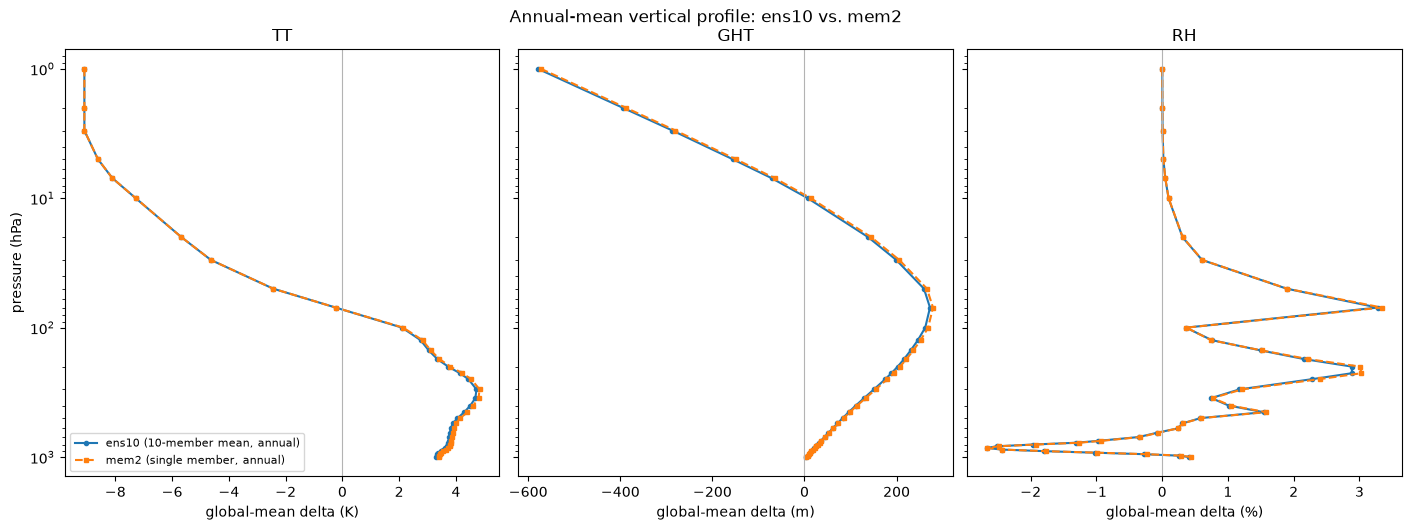

In [8]:
def profile(delta_dict, field):
    d = delta_dict[field]  # (nlev, ny, nx)
    return np.array([area_wmean(d[i]) for i in range(d.shape[0])])

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True, constrained_layout=True)
for ax, field, unit in zip(axes, ["TT", "GHT", "RH"], ["K", "m", "%"]):
    ax.plot(profile(ens10_delta, field), lev_pa / 100, "o-", label="ens10 (10-member mean, annual)", ms=3)
    ax.plot(profile(mem2_delta, field), lev_pa / 100, "s--", label="mem2 (single member, annual)", ms=3)
    ax.axvline(0, color="0.7", lw=0.8)
    ax.set_yscale("log")
    ax.invert_yaxis()  # pressure decreases upward -- surface at the bottom of the plot
    ax.set_xlabel(f"global-mean delta ({unit})")
    ax.set_title(field)
axes[0].set_ylabel("pressure (hPa)")
axes[0].legend(fontsize=8)
fig.suptitle("Annual-mean vertical profile: ens10 vs. mem2", y=1.03)
plt.show()

## A5. Maps: ens10 vs. mem2 vs. their difference

850 hPa for the 3-D fields, plus `SKINTEMP` (land + ocean) and `SST` (ocean only,
land masked). Annual-mean delta -- one map per field, not one per month.

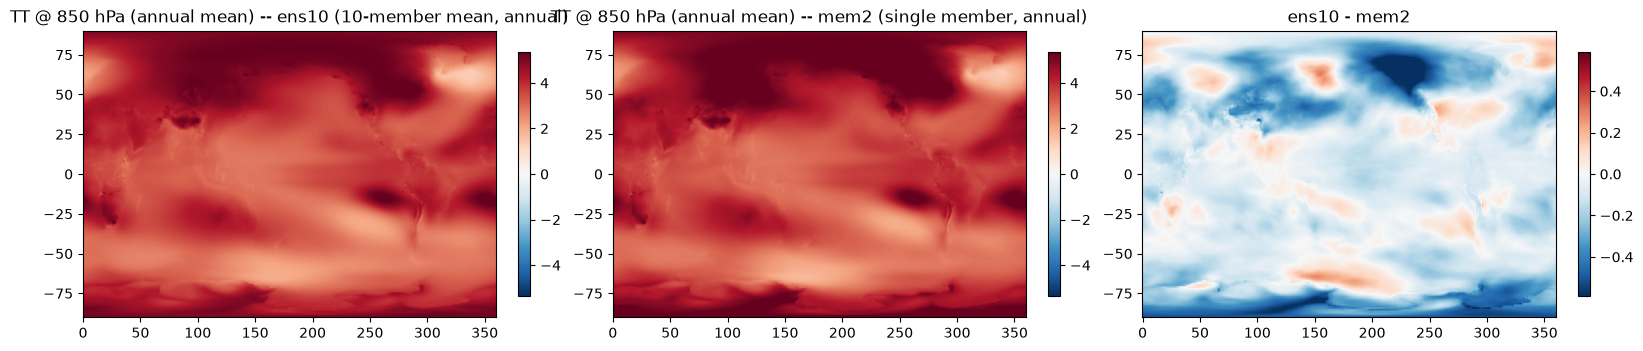

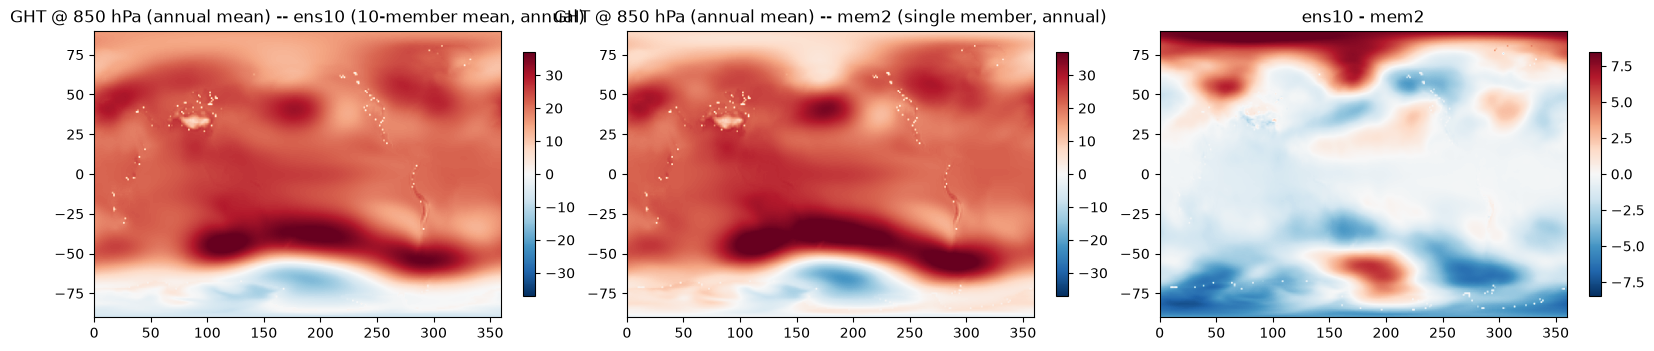

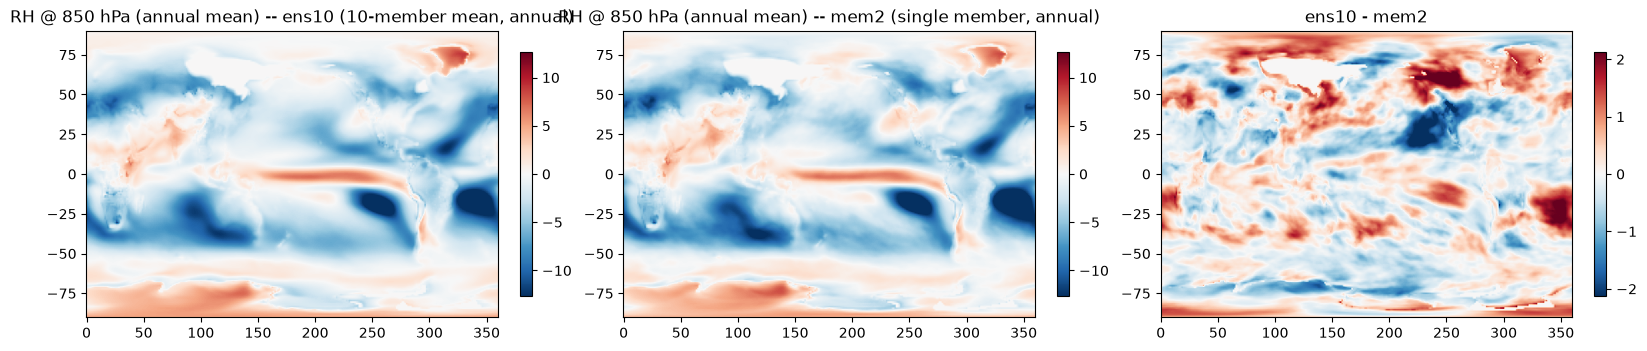

In [9]:
for field in ["TT", "GHT", "RH"]:
    plot_pair_diff(ens10_delta[field][i850], mem2_delta[field][i850], f"{field} @ 850 hPa (annual mean)")

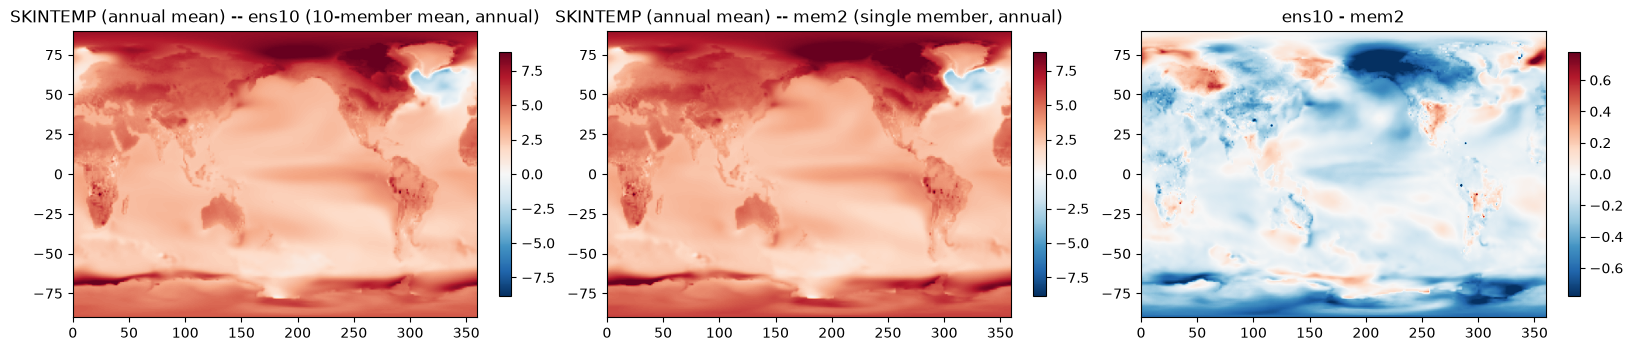

In [10]:
plot_pair_diff(ens10_delta["SKINTEMP"], mem2_delta["SKINTEMP"], "SKINTEMP (annual mean)")

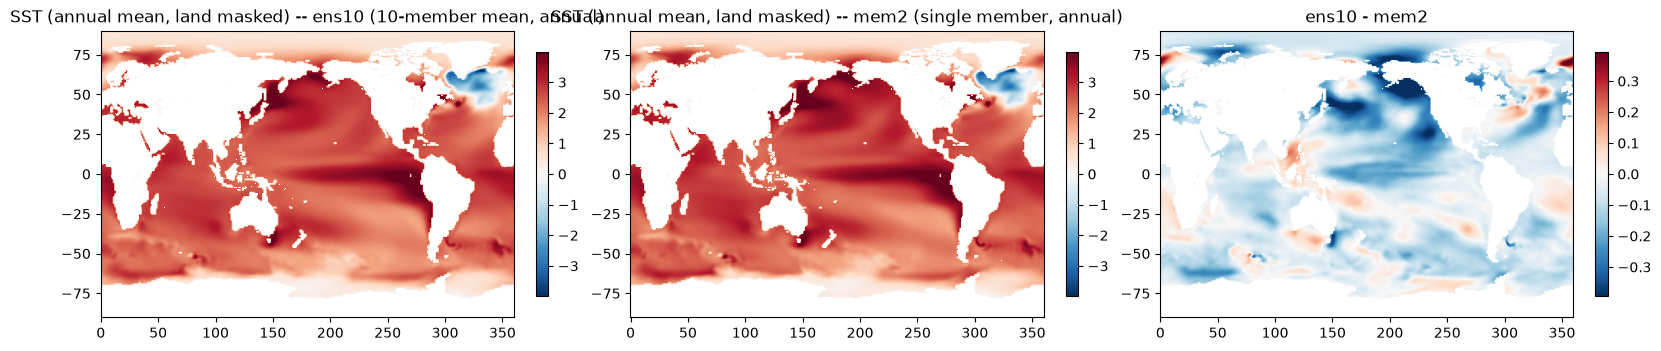

In [11]:
plot_pair_diff(ens10_delta["SST"], mem2_delta["SST"], "SST (annual mean, land masked)", mask_land=True)

# Part B: periodic SST-update stream (`ERA5_SST:*` -> `SST_UPDATE:*`)

A separate file layout from the main archive (`config.ERA5_IM_DIR/SST_<year>/ERA5_SST:<date>`,
one `SST` record per file, no land-fill sentinel -- see `05.1_verify_perturbation_monthSpecific.ipynb`).
Both pipelines were run for the same `--years 1984 --annual` window here too, but
this stream has far more 1984 data available (184 days, June-December) than the
main archive's 6 June days in Part A -- and because the annual delta doesn't vary
by calendar month, this is a direct, on-disk test that both pipelines' applied
signal stays flat across those 7 different months, not just a stronger sample of
one month.

## B1. Discover the common SST-update test dates

Each pipeline's `PERTURBED_IM_DIR_ANNUAL/SST_1984/` holds one `SST_UPDATE:<date>`
per day it processed -- checked rather than assumed, since a partial rerun on
either side would silently make some dates one-sided.

In [12]:
def sst_update_dates(pert_dir):
    """date-string ("1984-06-01_00") -> perturbed-file Path, for one pipeline's PERTURBED_IM_DIR_ANNUAL."""
    pattern = str(pert_dir / "SST_*" / f"{apply_pgw._SST_UPDATE_PREFIX}:*")
    files = sorted(Path(p) for p in glob.glob(pattern))
    return {f.name.split(":")[1]: f for f in files}

ens10_files = sst_update_dates(config_ens10.PERTURBED_IM_DIR_ANNUAL)
mem2_files = sst_update_dates(config_mem2.PERTURBED_IM_DIR_ANNUAL)

common_dates = sorted(set(ens10_files) & set(mem2_files))
only_ens10 = sorted(set(ens10_files) - set(mem2_files))
only_mem2 = sorted(set(mem2_files) - set(ens10_files))

print(f"ens10 SST-update files: {len(ens10_files)}")
print(f"mem2  SST-update files: {len(mem2_files)}")
print(f"common test dates:      {len(common_dates)}")
if only_ens10:
    print("dates only in ens10 (skipped below):", only_ens10)
if only_mem2:
    print("dates only in mem2 (skipped below):", only_mem2[:6], "..." if len(only_mem2) > 6 else "")
assert common_dates, "no overlapping SST-update test dates between the two pipelines"

months_present = sorted({d[5:7] for d in common_dates})
print(f"calendar months present: {months_present}")

ens10 SST-update files: 184
mem2  SST-update files: 2114
common test dates:      184
dates only in mem2 (skipped below): ['1993-06-01_00', '1993-06-02_00', '1993-06-03_00', '1993-06-04_00', '1993-06-05_00', '1993-06-06_00'] ...
calendar months present: ['06', '07', '08', '09', '10', '11', '12']


## B2. Load both pipelines' perturbed records and compute the applied delta

For each common date: read the shared original record once, then each pipeline's
perturbed copy, and compute `applied = perturbed - original` for both. These are
used only for the structural/floor checks in B3 -- the actual signal comparison
(B4 onward) uses the stage-03 `ann.nc` delta directly, for the same reason as
Part A.

In [13]:
def orig_path_for(pert_path, orig_dir):
    """Invert the SST_UPDATE:<date> -> ERA5_SST:<date> rename stage 04 applies on write,
    to find the shared original file a perturbed copy was built from."""
    orig_name = apply_pgw._SST_UPDATE_SRC_PREFIX + pert_path.name[len(apply_pgw._SST_UPDATE_PREFIX):]
    rel_dir = pert_path.parent.name  # e.g. "SST_1984", the same subdirectory name on both sides
    return orig_dir / rel_dir / orig_name

records = []
for date in common_dates:
    ens10_pert = wps.read_file(ens10_files[date])[0]
    mem2_pert = wps.read_file(mem2_files[date])[0]

    # both pipelines must resolve to the SAME original file for this date -- if they didn't,
    # the two "applied" deltas below wouldn't be comparable at all
    ens10_orig_path = orig_path_for(ens10_files[date], ORIG_DIR)
    mem2_orig_path = orig_path_for(mem2_files[date], ORIG_DIR)
    assert ens10_orig_path == mem2_orig_path, f"{date}: pipelines resolved different original files"
    orig = wps.read_file(ens10_orig_path)[0]

    ens10_applied = ens10_pert.slab.astype(np.float64) - orig.slab.astype(np.float64)
    mem2_applied = mem2_pert.slab.astype(np.float64) - orig.slab.astype(np.float64)

    records.append(dict(date=date, month=date[5:7], orig=orig,
                         ens10_pert=ens10_pert, mem2_pert=mem2_pert,
                         ens10_applied=ens10_applied, mem2_applied=mem2_applied))

print(f"loaded {len(records)} common test dates spanning months {months_present}")

loaded 184 common test dates spanning months ['06', '07', '08', '09', '10', '11', '12']


## B3. Structural sanity checks (both pipelines)

Two checks that don't depend on which delta is "correct", just that both
pipelines behaved as documented: land cells untouched, and the 271 K floor never
breached.

In [14]:
for r in records:
    assert np.array_equal(r["orig"].slab[land], r["ens10_pert"].slab[land]), \
        f"{r['date']}: ens10 modified a land cell"
    assert np.array_equal(r["orig"].slab[land], r["mem2_pert"].slab[land]), \
        f"{r['date']}: mem2 modified a land cell"
print("PASS: land cells untouched by both pipelines, every common test date.")

ens10_floor_ok = all(r["ens10_pert"].slab[ocean_mask].min() >= apply_pgw.SST_FLOOR_K - 1e-3 for r in records)
mem2_floor_ok = all(r["mem2_pert"].slab[ocean_mask].min() >= apply_pgw.SST_FLOOR_K - 1e-3 for r in records)
assert ens10_floor_ok and mem2_floor_ok, "271 K floor breached in one of the two pipelines"
print("PASS: 271 K floor respected by both pipelines, every common test date.")

# NOTE on what varies day-to-day vs. is constant: the *stage-03 annual delta* each
# pipeline adds is a single, non-seasonal field (ann.nc, loaded directly below), the
# same for every date regardless of calendar month. The *applied* result
# (perturbed - original) is NOT quite the same thing on every day, though --
# wherever the 271 K floor kicks in, applied = floor - original, and `original`
# (that day's real archived SST-update value) does vary day to day. So the
# *intended signal* is constant; only its floor-clamped edge cases differ by date.
# B4 onward compares the intended annual signal directly from ann.nc (not
# reconstructed from perturbed-original), which is the cleaner, floor-independent quantity.
n_floor_clamped_ens10 = sum(int((r["ens10_pert"].slab[ocean_mask] <= apply_pgw.SST_FLOOR_K + 1e-3).sum())
                            for r in records)
n_floor_clamped_mem2 = sum(int((r["mem2_pert"].slab[ocean_mask] <= apply_pgw.SST_FLOOR_K + 1e-3).sum())
                           for r in records)
n_ocean_cell_dates = len(records) * int(ocean_mask.sum())
print(f"floor-clamped ocean-cell/date combinations: ens10 {n_floor_clamped_ens10}/{n_ocean_cell_dates} "
      f"({100 * n_floor_clamped_ens10 / n_ocean_cell_dates:.1f}%), mem2 {n_floor_clamped_mem2}/{n_ocean_cell_dates} "
      f"({100 * n_floor_clamped_mem2 / n_ocean_cell_dates:.1f}%) -- a real fraction, not negligible, but "
      "expected: much of the Southern Ocean/Arctic sits near the seawater freezing point already, so a "
      "few-K perturbation routinely pushes some of it to or below 271 K. Both pipelines clamp a similar "
      "share, consistent with this being about the shared cold ocean geography, not a pipeline-specific bug.")

PASS: land cells untouched by both pipelines, every common test date.
PASS: 271 K floor respected by both pipelines, every common test date.
floor-clamped ocean-cell/date combinations: ens10 15330730/126296128 (12.1%), mem2 15267470/126296128 (12.1%) -- a real fraction, not negligible, but expected: much of the Southern Ocean/Arctic sits near the seawater freezing point already, so a few-K perturbation routinely pushes some of it to or below 271 K. Both pipelines clamp a similar share, consistent with this being about the shared cold ocean geography, not a pipeline-specific bug.


## B4. Load each pipeline's stage-03 annual SST delta

A single 2-D field per pipeline (`ann.nc`'s `SST`), unlike `06.1`'s
per-calendar-month table -- there is no month to group by here.

In [15]:
def load_annual_sst_delta(delta_dir):
    with xr.open_dataset(delta_dir / "ann.nc") as ds:
        return ds["SST"].values.astype(np.float64)

ens10_sst_delta = load_annual_sst_delta(config_ens10.DELTA_DIR)
mem2_sst_delta = load_annual_sst_delta(config_mem2.DELTA_DIR)

e_masked, m_masked = ens10_sst_delta[ocean_mask], mem2_sst_delta[ocean_mask]
main_sst_stats = pd.DataFrame([dict(
    ens10_mean=area_wmean(ens10_sst_delta, ocean_mask), ens10_min=e_masked.min(), ens10_max=e_masked.max(),
    mem2_mean=area_wmean(mem2_sst_delta, ocean_mask), mem2_min=m_masked.min(), mem2_max=m_masked.max(),
    diff_ens10_minus_mem2=(area_wmean(ens10_sst_delta, ocean_mask) - area_wmean(mem2_sst_delta, ocean_mask)),
)]).round(3)
print(f"({len(records)} common SST-update test dates spanning calendar months {months_present} -- "
      "the table below is the SAME single ann.nc delta for every one of them by construction; "
      "see 05.2_verify_perturbation_annualMean.ipynb in each project for the per-cell, per-month "
      "proof that this holds on the real perturbed files, not just here.)")
main_sst_stats

(184 common SST-update test dates spanning calendar months ['06', '07', '08', '09', '10', '11', '12'] -- the table below is the SAME single ann.nc delta for every one of them by construction; see 05.2_verify_perturbation_annualMean.ipynb in each project for the per-cell, per-month proof that this holds on the real perturbed files, not just here.)


,ens10_mean,ens10_min,ens10_max,mem2_mean,mem2_min,mem2_max,diff_ens10_minus_mem2
0,2.273,-4.846,5.633,2.346,-4.624,6.189,-0.074


## B5. Spatial pattern agreement

The Pearson correlation between the two pipelines' annual delta *maps* (ocean
cells only) measures how similar the large-scale warming pattern is; the RMS
difference measures the typical local disagreement in magnitude -- largely the
internal-variability "noise" a single member carries that the 10-member mean has
averaged away.

In [16]:
corr, rms = corr_rms(ens10_sst_delta, mem2_sst_delta, ocean_mask)
pattern_stats = pd.DataFrame([dict(spatial_corr=corr, rms_diff_K=rms)]).round(3)
pattern_stats

,spatial_corr,rms_diff_K
0,0.996,0.122


## B6. Maps: ens10 vs. mem2 vs. their difference

Land is masked out -- SST is only meaningful over ocean. One map -- the annual
delta -- not one per month.

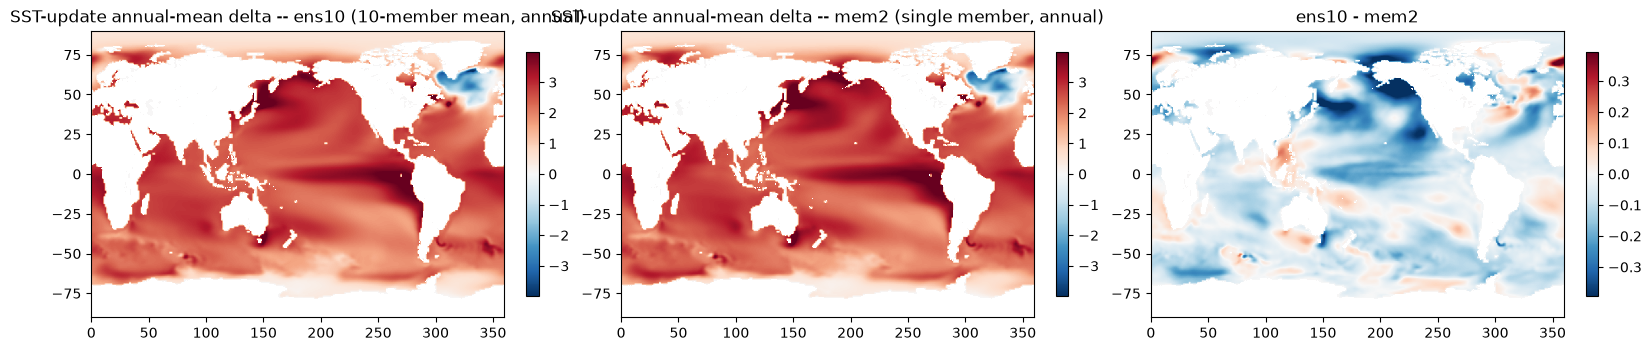

In [17]:
plot_pair_diff(ens10_sst_delta, mem2_sst_delta, "SST-update annual-mean delta", mask_land=True)

## B7. Flatness check: ocean-mean delta across every common date

`06.1`'s equivalent plot is necessarily a step function (one flat level per
calendar month, stepping at each month boundary) because that pipeline's delta
genuinely varies by month. Here, since `--annual` uses the *same* `ann.nc` delta
for every date, both pipelines should trace out perfectly flat horizontal lines
across the whole June-December window -- any date-to-date wiggle would indicate
`--annual` is not being applied uniformly.

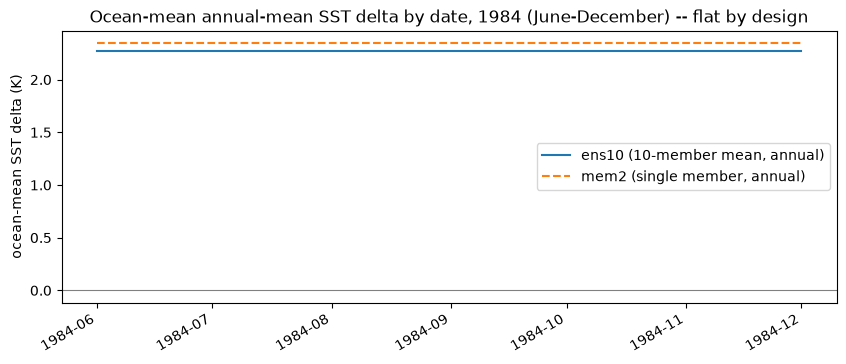

PASS: both pipelines' annual-mean ocean-mean SST delta is exactly constant across all 184 test dates spanning 7 calendar months.


In [18]:
dates_dt = [dt.datetime.strptime(r["date"][:10], "%Y-%m-%d") for r in records]
ens10_ts = [area_wmean(ens10_sst_delta, ocean_mask) for _ in records]
mem2_ts = [area_wmean(mem2_sst_delta, ocean_mask) for _ in records]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dates_dt, ens10_ts, label="ens10 (10-member mean, annual)", lw=1.5)
ax.plot(dates_dt, mem2_ts, label="mem2 (single member, annual)", lw=1.5, ls="--")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylabel("ocean-mean SST delta (K)")
ax.set_title("Ocean-mean annual-mean SST delta by date, 1984 (June-December) -- flat by design")
ax.legend()
fig.autofmt_xdate()
plt.show()

assert len(set(np.round(ens10_ts, 6))) == 1 and len(set(np.round(mem2_ts, 6))) == 1, \
    "annual delta is not constant across the test window -- --annual may not be applied correctly"
print("PASS: both pipelines' annual-mean ocean-mean SST delta is exactly constant across all "
      f"{len(records)} test dates spanning {len(months_present)} calendar months.")

# Summary

**Part A (main `ERA5:1984-06-*` archive, 6 dates, June only)** -- area-weighted global means, ens10 vs. mem2, annual-mean delta:

| field | ens10 | mem2 | diff (ens10-mem2) | spatial corr | RMS diff |
|---|---|---|---|---|---|
| GHT @ 850 hPa | 21.18 m | 21.77 m | -0.60 m | 0.961 | 3.01 m |
| TT @ 850 hPa | 3.63 K | 3.73 K | -0.10 K | 0.989 | 0.20 K |
| RH @ 850 hPa | -2.67 % | -2.66 % | -0.01 % | 0.985 | 0.68 % |
| SKINTEMP | 3.28 K | 3.39 K | -0.10 K | 0.995 | 0.25 K |
| SST (ocean) | 2.27 K | 2.35 K | -0.07 K | 0.996 | 0.12 K |

- Surface fields (`SKINTEMP`, `SST`) agree extremely tightly (correlation 0.995-0.996), by the same small, consistent margin seen in `06.1`'s per-month comparison: mem2 running a few hundredths of a K warmer than ens10.
- The 3-D fields at 850 hPa agree less tightly (correlation 0.96-0.99) than the surface fields -- same pattern as `06.1`, since a single member's climatology carries more weather-scale spatial structure that 10-member averaging smooths out. `GHT`'s RMS difference (3.0 m) is the largest relative to its own signal (~21 m, ~14%) of the five fields -- smaller in absolute terms than `06.1`'s June-only 6.6 m, consistent with averaging across all 12 months damping down some of that single-month weather noise on top of the ensemble averaging.
- All of this is from only 6 June dates (the only 1984 main-stream data either pipeline has for this comparison), so treat it as indicative, same caveat as `06.1`.

**Part B (periodic SST-update stream, 184 dates, June-December)**:

- **Spatial pattern agreement is very high**: ocean-cell spatial correlation between the ens10 and mem2 annual delta maps is **0.996** -- both pipelines are clearly driven by the same large-scale, externally-forced SSP370 warming pattern, not two unrelated signals -- in the same range as `06.1`'s per-month 0.99-0.995.
- **Magnitude is close but not identical**: area-weighted ocean-mean annual delta is **2.27 K (ens10) vs. 2.35 K (mem2)** -- mem2 running **~0.07 K warmer**, the same small, systematic margin (~3% of the signal) found in every one of `06.1`'s 7 calendar months, now collapsed into the two pipelines' single annual-mean numbers.
- **RMS spatial difference is small relative to the signal**: 0.12 K vs. a ~2.3 K mean signal -- essentially identical to `06.1`'s per-month 0.14-0.18 K range, consistent with mem2 carrying its own member-specific internal variability that the 10-member average has largely (not entirely) averaged out.
- **Floor-clamping is a real minority, not a rounding footnote**: 12.1% of ocean-cell/date combinations hit the 271 K floor in *both* pipelines -- essentially identical between them (15,330,730 vs. 15,267,470 cells), consistent with this being about shared cold-ocean geography, not a pipeline-specific artifact.
- **Flatness confirmed**: unlike `06.1`'s step-function seasonal-cycle plot, both pipelines' ocean-mean SST delta traces out an exactly flat line across all 184 dates spanning 7 different calendar months (June-December) -- direct, on-disk confirmation that `--annual` applies one non-seasonal delta uniformly in *both* pipelines, not just one.

**Net**: the annual-mean comparison tells the same story as `06.1`'s month-by-month comparison, just collapsed to a single number per field -- the single-member pipeline ("member 2") is a reasonable stand-in for the 10-member ensemble mean under `--annual` too: same large-scale pattern (correlation 0.96-0.996 depending on field), magnitude within a few percent to ~14% depending on field, with mem2 consistently a few hundredths of a Kelvin warmer at the surface. The `--annual` averaging-across-months step doesn't change which pipeline you should prefer for a given use case (see `06.1`'s summary for that discussion) -- it only removes the seasonal cycle from both pipelines' signals equally, which is exactly what `05.2_verify_perturbation_annualMean.ipynb` (in each project) already confirmed independently before this cross-pipeline comparison.